<a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/heeyeon/advanced/heeyeon/session07/%EC%8B%9C%EA%B3%84%EC%97%B4_%EC%82%AC%EC%A0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 시계열 분석 사전과제 정리

---

## 1. 시계열 데이터란?

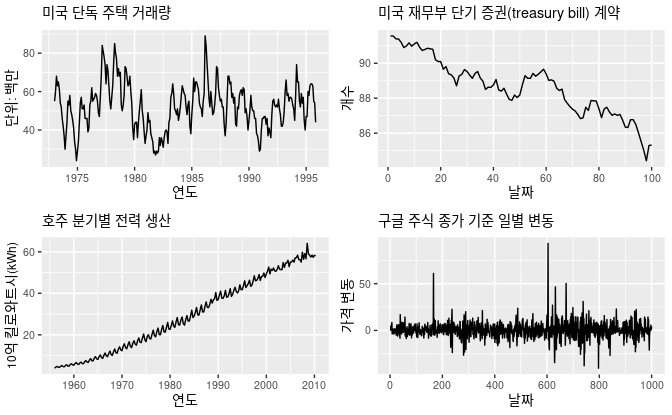

### 1-1. 시계열 데이터의 정의
- 시간의 흐름에 따라 일정한 간격으 기록하는 데이터
- 관측값의 순서 의미를 가짐
- 분석 목적: 과거 패턴 이해, 미래 값 예측

### 1-2. 시계열 데이터의 특성
- 시간 의존성: 현재 값이 과거 값과 상관관계를 가짐 → 독립성 가정 불성립
- 순서 고정: 데이터 셔플 불가, train/test도 시간 순서대로 분할
자기상관성: 과거가 주는 영향이 얼마나 강한지 숫자로 수치화  
- 비정상성: 평균·분산이 시간에 따라 변하는 경우가 많음
- 단일 관측: 각 시점마다 관측값이 하나뿐
- 불규칙성: 설명할 수 없는 랜덤 노이즈

### 1-3. 시계열 데이터의 분석요인
- 추세: 장기적인 증가/감소 경향
- 계절: 고정된 주기로 반복되는 패턴
- 순환: 주기가 일정하지 않은 장기 변동
- 불규칙: 랜덤 변동

---

## 2. 시계열 데이터 전처리

### 2-1. 결측치 / 이상치 처리
- 결측치
  - 행 삭제 시 시간 간격이 깨지므로 삭제보다 대체를 우선함
  - 잘못된 값 하나가 특성을 크게 왜곡시킴
  -> 삭제/단순 대치/보간/이동평균 대치/머신러닝 기법    

- 이상치: 일반 패턴에서 크게 벗어난 값   
  - 탐지: 시각화, IQR, Z-score, 이동평균 기반 범위, 요소분해 후 잔차 확인
  - 처리: 결측 처리 후 보간, 상·하한값으로 대체, 실제 이벤트라면 유지

전처리 프로세스
```python
① 데이터 확인         → 시간 인덱스 정리, 관측 간격 확인, 시각화
↓
② 결측치 탐지 & 처리   → 빠진 값을 찾아 합리적으로 채우기          (2-1)
↓
③ 이상치 탐지 & 처리   → 튀는 값을 찾아 삭제하거나 대체하기        (2-1)
↓
④ 평활화              → 노이즈를 줄여 큰 흐름 파악하기            (2-2)
↓
⑤ 요소분해            → 추세·계절·불규칙 요인으로 나눠 보기        (2-3)
↓
⑥ 정상성 판단 & 확보   → 모델에 넣을 수 있는 상태로 만들기         (3장)
```

### 2-2. 평활화
- 노이즈를 줄여 추세·패턴을 잘 드러나게 하는 기법
- 이동평균: 일정 구간 값의 평균 사용, 구간이 길수록 매끄럽지만 변화 반영이 늦음


### 2-3. 요소 분해
- 시계열을 추세 / 계절 / 잔차로 분리

#### 가법모형 / 승법모형
- 가법모형: Y = T + S + I
  - 계절 변동의 폭이 일정할 때, 혹은 추세가 커질수록 계절 변동의 폭도 커질 때 사용    




-> 강한 정상성을 만족하는 데이터는 거으 ㅣ현실에 없다.

---

## 3. 정상성 판단: 일정 수평선 중심 위아래로   

### 3-1. 정상성의 정의
- 시계열의 통계적 성질이 시간에 따라 변하지 않는 상태. AR, MA, ARMA 모형은 정상성을 전제로 함
- 대표 예시: 백색잡음(평균 0, 분산 일정, 자기상관 없음)

### 3-2. 강한 정상성 / 약한 정상성
- 강한 정상성: 모든 시점 조합의 결합분포가 시간 이동에 대해 변하지 않음, 현실에서 확인이 어려움
- 약한 정상성:   
  - 평균이 일정함
  - 분산이 일정함
  - 공분산이 시점이 아닌 시차에만 의존함

### 3-3. 정상성의 판단
- 시각적 판단
  - 시계열 플롯에서 추세 변화 확인
  - 이동평균,이동표준편차의 일정 여부 확인
  - ACF가 빠르게 0으로 감소하면 정상, 천천히 감소하면 비정상
- 통계적 판단
  - ADF 검정: 귀무가설 = 비정상(단위근 존재)     

단위근 = 0.5 (정상) : 매일 절반씩만 남으니까 충격이 점점 작아지다 사라짐. 그래서 값이 튀어도 결국 평균으로 돌아돔 -> adf, kpss

### 3-4. 정상성 확보 방법
깨지는 원인: 추세, 계절성, 분산변화   
-> 추세 제거와 차분 필요    
- 로그 변환 / Box-Cox 변환: 분산 안정화
차분: 현재 값에서 이전 값을 빼서 추세 제거
계절 차분: 한 주기 전 값을 빼서 계절성 제거
과도한 차분은 오히려 분산을 키우므로 보통 1~2회로 충분
---

## 4. 단변량 시계열 분석

### 4-1. 안정적 시계열 분석

#### AR / MA
- AR 자기회귀 모형
  - 현재 값을 자기 자신의 과거 값들로 설명함 자기상관성 활용   
  - 차수 p: 사용하는 과거 시점의 수
- MA 모형
  - 현재 값을 과거의 오차(충격)들로 설명함
  - 차수 q: 사용하는 과거 오차의 수


#### AR, MA의 전제조건
- 공통: 데이터가 정상 시계열이고, 오차가 백색잡음   정상성: 충격을 받아도 원래대로 돌아옴   
- AR: 정상성 조건 필요
- MA: 가역성 조건 필요 (MA(1)이면 계수의 절댓값 < 1), AR 형태로 전환할 수 있어야 모형이 하나로 정해짐

#### ARMA
- AR과 MA를 결합한 모형, ARMA(p, q)로 표기함
- 적은 파라미터로 복잡한 패턴을 간결하게 표현할 수 있음
- 정상 시계열을 전제로 함

#### 차수 결정 방법 : 자기 상관 함수 (ACF, PACF)

현재 값과 k시점 전 값의 상관, 중간 시점의 영향을 포함함
부분 자기 상관계수
- PACF: 중간 시점의 영향을 제거한 순수한 상관


차수 결정 규칙
AR(p): ACF는 천천히 감소, PACF는 p 이후 절단 → PACF로 p 결정
  - MA(q): ACF는 q 이후 절단, PACF는 천천히 감소 → ACF로 q 결정
  - ARMA: 둘 다 천천히 감소 → AIC·BIC가 가장 작은 조합 선택


### 4-2. 불안정 시계열 분석

#### ARIMA
- 비정상 시계열을 d번 차분해 정상화한 뒤 ARMA를 적용하는 모형, arma에 차분을 더한 모형   
- ARIMA(p, d, q): p = AR 차수, d = 차분 횟수, q = MA 차수, 계절성은 반영하지 못함
랜덤워크, 표류 포함   

#### SARIMA
- ARIMA에 계절 성분을 추가한 모형
 계절 AR 차수, 계절 차분, 증감 예측, 판매량 되돌림  ->  외부 변수를 추가하면 SARIMAX가 됨

#### 분석 절차 (Box-Jenkins)
- 전처리 → 정상화(차분) → 차수 결정(ACF·PACF) → 모형 적합 → 잔차 진단 → 예측

계절 차분을 먼저 수행하는 것이 중요   

---

## 5. 다변량 시계열 분석

### 5-1. VAR
새원리가 아니라 변수를 여러 개로 넓힌것이다..   

X_t = a_1 X_{t-1} + \varepsilon_t

- 여러 시계열 변수가 서로 영향을 주고받음(양방향), 즉 각 변수를 자신의 과거 값과 다른 변수들의 과거 값으로 설명함
- AR을 여러 변수로 확장한 형태이며, 모든 변수를 내생변수로 취급함 전제조건: 모든 변수가정상, 혹은 수가 적고 데이터가 충분   

-> 충격 반응 함수 / 예측 오차 분산 분해 "누구의 영향이 얼마나 큰가"


- 활용
  - 그랜저 인과성 검정: 한 변수의 과거 값이 다른 변수 예측에 도움이 되는지 검정
  - 충격반응함수(IRF): 한 변수의 충격에 다른 변수가 시간에 따라 어떻게 반응하는지 확인
- 한계: 변수와 시차가 늘면 파라미터 수가 급증해 과적합 위험이 커짐